In [1]:
#loading libraries:
import pandas as pd
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv("Churn_Modelling.xls")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.drop(columns=["RowNumber","CustomerId","Surname"],inplace=True)

In [6]:
label = LabelEncoder()
df["encoded_geo"] = label.fit_transform(df["Geography"])
var = dict(zip(df["Geography"],df["encoded_geo"]))
print(var)

df["encoded_gender"] = label.fit_transform(df["Gender"])
var1 = dict(zip(df["Gender"],df["encoded_gender"]))
print(var1)

{'France': 0, 'Spain': 2, 'Germany': 1}
{'Female': 0, 'Male': 1}


In [7]:
df.drop(columns=["Gender","Geography"],inplace=True)

In [8]:
#feature selection:
x = df.drop(columns=["Exited"])
y = df["Exited"]

In [11]:
#data splitting:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [12]:
#scaling:
scaler = StandardScaler()
x_train_scaled =  scaler.fit_transform(x_train)
x_test_scaled =  scaler.transform(x_test)

In [31]:
#ANN architecture:
model = Sequential()
#input layer:
model.add(Dense(512,activation="sigmoid",input_dim=(10)))
model.add(BatchNormalization())
#drop out layer:
model.add(Dropout(0.1))
#hidden layer
model.add(Dense(256,activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.1))
model.add(Dense(128,activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.1))
model.add(Dense(64,activation="relu"))
model.add(BatchNormalization())
model.add(Dropout(0.1))

#output layer:
model.add(Dense(1,activation="sigmoid"))
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 512)            │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 182,017 (711.00 KB)

 Trainable params: 180,097 (703.50 KB)

 Non-trainable params: 1,920 (7.50 KB)

In [32]:
#model compile:
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [ ]:
#applying early stopping:
#early = EarlyStopping(monitor="val_loss",
  #                    patience= 5,
   #                   restore_best_weights=True)

In [44]:
#model fit:
history = model.fit(x_train_scaled,y_train,verbose=1,batch_size=32,epochs =100 ,validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8573 - loss: 0.3415 - val_accuracy: 0.8656 - val_loss: 0.3353
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8553 - loss: 0.3386 - val_accuracy: 0.8637 - val_loss: 0.3354
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8584 - loss: 0.3343 - val_accuracy: 0.8556 - val_loss: 0.3446
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8581 - loss: 0.3380 - val_accuracy: 0.8550 - val_loss: 0.3395
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8589 - loss: 0.3335 - val_accuracy: 0.8556 - val_loss: 0.3467
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8602 - loss: 0.3336 - val_accuracy: 0.8675 - val_loss: 0.3398
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8617 - loss: 0.3323 - val_accuracy: 0.8712 - val_loss: 0.3363
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8611 - loss: 0.3350 - val

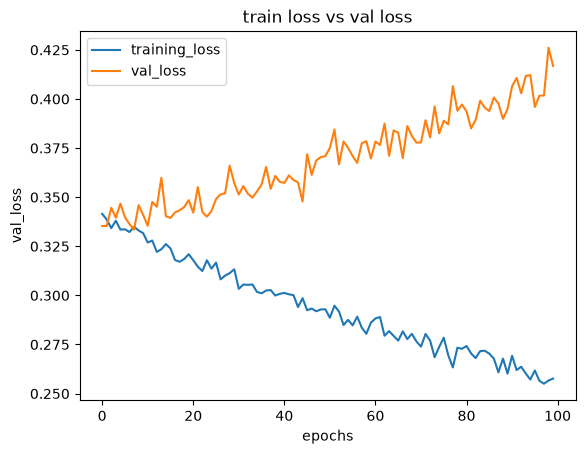

In [45]:
#plot:
plt.plot(history.history["loss"],label = "training_loss")
plt.plot(history.history["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("val_loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

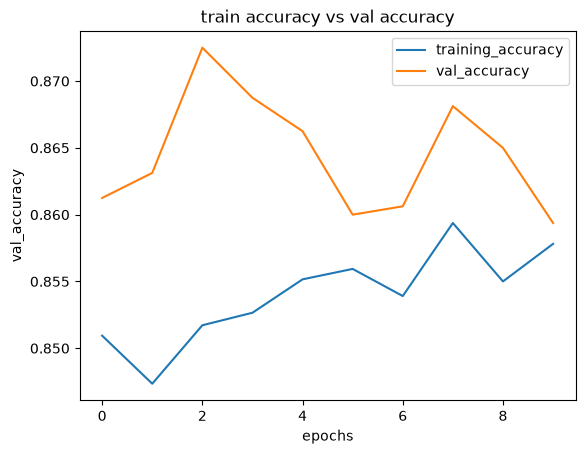

In [42]:
#plot:
plt.plot(history.history["accuracy"],label = "training_accuracy")
plt.plot(history.history["val_accuracy"],label="val_accuracy")
plt.xlabel("epochs")
plt.ylabel("val_accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()